#  — Task 2: Exploratory Data Analysis (EDA)

**Dataset:** `Ecommerce_Dataset_3000.csv`

This notebook analyzes a 3,000-row sample of e-commerce orders. Results apply to this sample only, not necessarily the full original dataset.

## 1. Questions to investigate
-How many rows and columns are present, and what are the variable types?
- Which product categories and order statuses are most common?
- What percentage of records are cancelled?
- How are order amounts distributed?
- Which fulfilment and shipping levels are most common?
- Which shipping states appear most often?
- Do expedited and standard shipping orders have different average amounts?
- What data-quality issues exist?

## 2. Load libraries and dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_FILE = Path("Ecommerce_Dataset_3000.csv")
df = pd.read_csv(DATA_FILE, low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3000, 24)


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


## 3. Explore data structure

In [2]:
print("Rows:", df.shape[0], "Columns:", df.shape[1])
print("Column names:", df.columns.tolist())
display(df.dtypes.astype(str).rename("data_type").to_frame())
display(df.describe(include="all").T)

Rows: 3000 Columns: 24
Column names: ['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by', 'Unnamed: 22']


,data_type
index,int64
Order ID,str
Date,str
Status,str
Fulfilment,str
Sales Channel,str
ship-service-level,str
Style,str
SKU,str
Category,str


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,3000.0,NaN,NaN,NaN,1499.5,866.169729,0.0,749.75,1499.5,2249.25,2999.0
Order ID,3000,2830,171-2644368-7969167,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,3000,3,04-30-22,1481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,3000,5,Shipped,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfilment,3000,2,Amazon,2307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Channel,3000,2,Amazon.in,2998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship-service-level,3000,2,Expedited,2271,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Style,3000,641,JNE3405,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SKU,3000,1482,JNE3405-KR-L,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3000,8,Set,1228,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data quality checks

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_percent": (missing/len(df)*100).round(2)})
display(missing_summary[missing_summary.missing_count > 0])
print("Exact duplicate rows:", df.duplicated().sum())
empty_columns = [c for c in df.columns if df[c].isna().all()]
print("Completely empty columns:", empty_columns)
for col in ["Qty", "Amount"]:
    print("\n", col); print(pd.to_numeric(df[col], errors="coerce").describe())
dates = pd.to_datetime(df["Date"], errors="coerce")
print("Unparseable dates:", dates.isna().sum(), "Date range:", dates.min(), "to", dates.max())

,missing_count,missing_percent
Unnamed: 22,3000,100.00
fulfilled-by,2307,76.90
promotion-ids,1085,36.17
currency,220,7.33
Amount,220,7.33
Courier Status,133,4.43
ship-country,2,0.07
ship-city,2,0.07
ship-state,2,0.07
ship-postal-code,2,0.07


Exact duplicate rows: 0
Completely empty columns: ['Unnamed: 22']

 Qty
count    3000.000000
mean        0.901333
std         0.407824
min         0.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        15.000000
Name: Qty, dtype: float64

 Amount
count    2780.000000
mean      624.411169
std       274.855094
min         0.000000
25%       432.000000
50%       574.000000
75%       771.000000
max      2224.000000
Name: Amount, dtype: float64
Unparseable dates: 0 Date range: 2022-04-28 00:00:00 to 2022-04-30 00:00:00


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18052\2627324583.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(df["Date"], errors="coerce")


## 5. Prepare analysis copy

In [4]:
eda = df.copy()
empty_columns = [c for c in eda.columns if eda[c].isna().all()]
eda = eda.drop(columns=empty_columns)
eda.columns = eda.columns.str.strip()
eda["Date"] = pd.to_datetime(eda["Date"], errors="coerce")
eda["Amount"] = pd.to_numeric(eda["Amount"], errors="coerce")
eda["Qty"] = pd.to_numeric(eda["Qty"], errors="coerce")
print("Original shape:", df.shape, "Analysis copy:", eda.shape)
print("Dropped completely empty columns:", empty_columns)

Original shape: (3000, 24) Analysis copy: (3000, 23)
Dropped completely empty columns: ['Unnamed: 22']


C:\Users\ASUS\AppData\Local\Temp\ipykernel_18052\3481400749.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  eda["Date"] = pd.to_datetime(eda["Date"], errors="coerce")


## 6. Product categories and order status

,count
Category,
Set,1228
kurta,1184
Western Dress,284
Top,257
Blouse,19
Ethnic Dress,17
Bottom,7
Saree,4


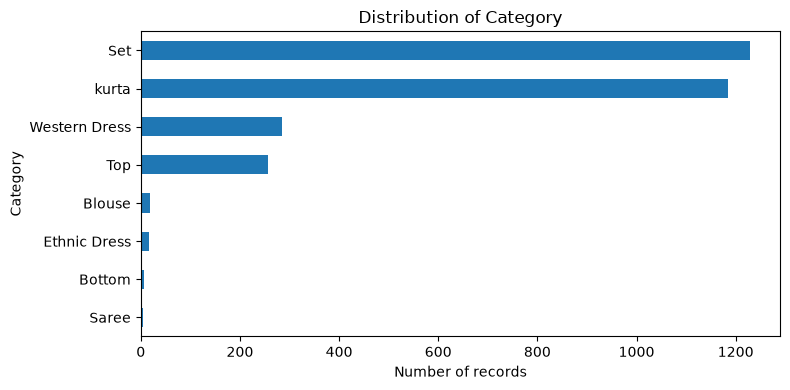

,count
Status,
Shipped,2002
Shipped - Delivered to Buyer,528
Cancelled,438
Shipped - Returned to Seller,31
Shipped - Rejected by Buyer,1


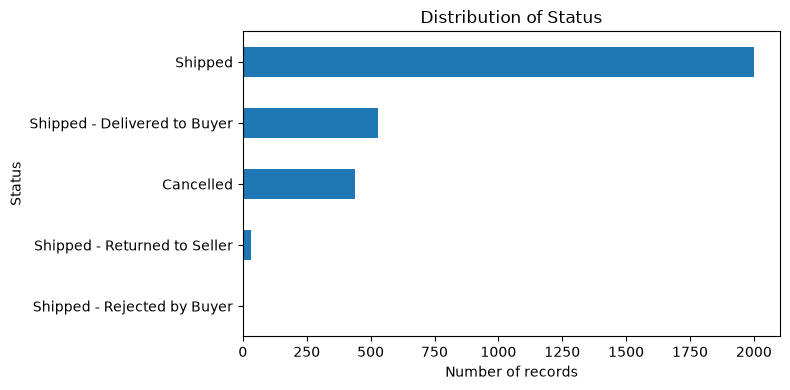

,count
Fulfilment,
Amazon,2307
Merchant,693


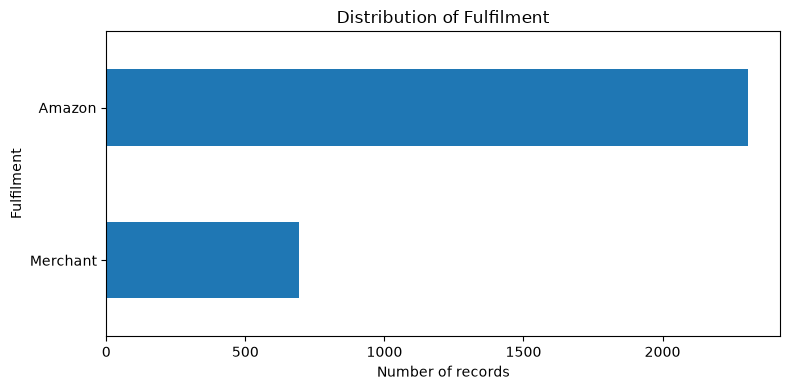

,count
ship-service-level,
Expedited,2271
Standard,729


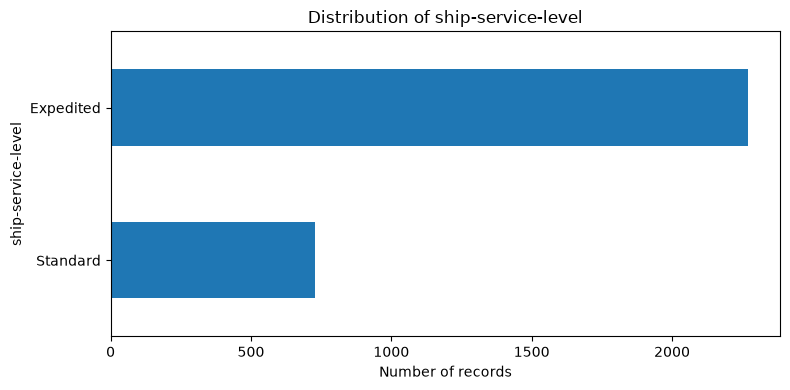

In [6]:
for col in ["Category", "Status", "Fulfilment", "ship-service-level"]:
    counts = eda[col].fillna("Missing").value_counts()
    display(counts.rename("count").to_frame())
    ax = counts.sort_values().plot(kind="barh", figsize=(8,4), title=f"Distribution of {col}")
    ax.set_xlabel("Number of records"); ax.set_ylabel(col)
    plt.tight_layout(); plt.show()

## 7. Order amount distribution

,count,mean,std,min,25%,50%,75%,max
Qty,3000.0,0.901333,0.407824,0.0,1.0,1.0,1.0,15.0
Amount,2780.0,624.411169,274.855094,0.0,432.0,574.0,771.0,2224.0


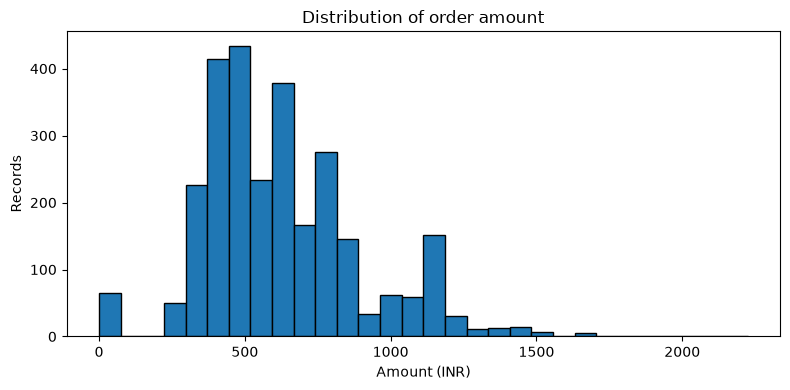

C:\Users\ASUS\AppData\Local\Temp\ipykernel_18052\1685455273.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.figure(figsize=(7,3)); plt.boxplot(amounts, vert=False)


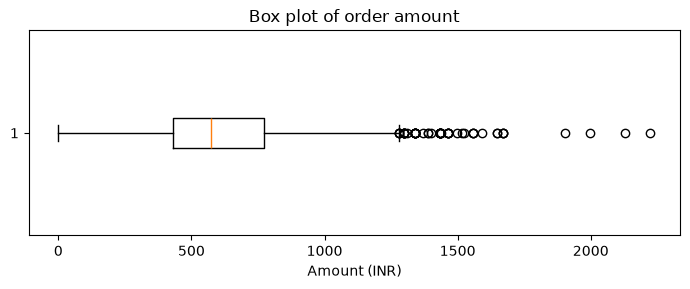

In [7]:
display(eda[["Qty", "Amount"]].describe().T)
amounts = eda["Amount"].dropna()
plt.figure(figsize=(8,4)); plt.hist(amounts, bins=30, edgecolor="black")
plt.title("Distribution of order amount"); plt.xlabel("Amount (INR)"); plt.ylabel("Records")
plt.tight_layout(); plt.show()
plt.figure(figsize=(7,3)); plt.boxplot(amounts, vert=False)
plt.title("Box plot of order amount"); plt.xlabel("Amount (INR)"); plt.tight_layout(); plt.show()

## 8. Shipping states

,records
ship-state,
MAHARASHTRA,517
KARNATAKA,380
TELANGANA,281
TAMIL NADU,252
UTTAR PRADESH,239
WEST BENGAL,155
DELHI,132
Gujarat,132
KERALA,121


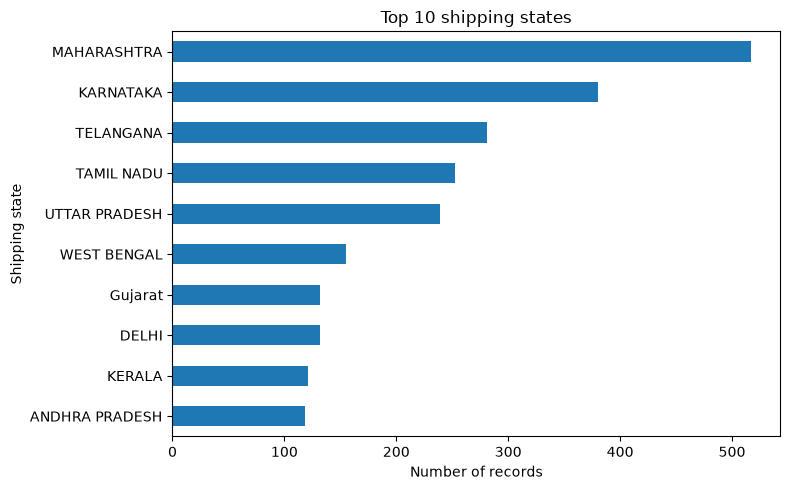

In [8]:
state_counts = eda["ship-state"].fillna("Missing").value_counts().head(10)
display(state_counts.rename("records").to_frame())
ax = state_counts.sort_values().plot(kind="barh", figsize=(8,5), title="Top 10 shipping states")
ax.set_xlabel("Number of records"); ax.set_ylabel("Shipping state")
plt.tight_layout(); plt.show()

## 9. Hypothesis testing

In [9]:
# Hypothesis 1: fewer than 20% of records have a cancelled status.
cancelled = eda["Status"].fillna("").str.lower().str.contains("cancel")
rate = cancelled.mean()*100
print(f"Cancelled records: {cancelled.sum()} / {len(eda)} ({rate:.2f}%)")
print("Hypothesis (<20% cancelled):", "SUPPORTED in this sample" if rate < 20 else "NOT SUPPORTED in this sample")

# Compare order amounts for expedited and standard shipping.
display(eda.dropna(subset=["Amount", "ship-service-level"]).groupby("ship-service-level")["Amount"].agg(["count","mean","median"]))
try:
    from scipy.stats import ttest_ind
    exp = eda.loc[eda["ship-service-level"].eq("Expedited"), "Amount"].dropna()
    std = eda.loc[eda["ship-service-level"].eq("Standard"), "Amount"].dropna()
    stat, p = ttest_ind(exp, std, equal_var=False)
    print(f"Welch t-test statistic={stat:.3f}, p-value={p:.4f}")
    print("At 5% significance:", "evidence of a difference" if p < 0.05 else "no statistically significant difference detected")
except ImportError:
    print("Install scipy from requirements.txt to run the t-test.")

Cancelled records: 438 / 3000 (14.60%)
Hypothesis (<20% cancelled): SUPPORTED in this sample


,count,mean,median
ship-service-level,,,
Expedited,2088,641.311782,597.0
Standard,692,573.416257,533.5


Welch t-test statistic=5.260, p-value=0.0000
At 5% significance: evidence of a difference


## 10. Average amount by category

,records,average_amount,median_amount
Category,,,
Set,1136,815.856673,788.0
Western Dress,259,732.983127,744.0
Top,245,490.339755,493.0
kurta,1094,431.295859,406.0


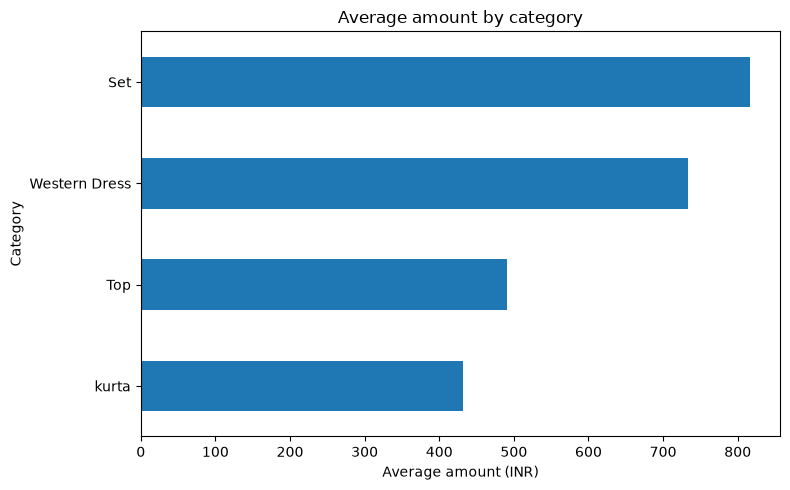

In [10]:
category_amount = (eda.dropna(subset=["Amount"]).groupby("Category")["Amount"]
    .agg(records="count", average_amount="mean", median_amount="median")
    .query("records >= 20").sort_values("average_amount", ascending=False))
display(category_amount)
if not category_amount.empty:
    ax = category_amount["average_amount"].sort_values().plot(kind="barh", figsize=(8,5), title="Average amount by category")
    ax.set_xlabel("Average amount (INR)"); ax.set_ylabel("Category")
    plt.tight_layout(); plt.show()

## 11. Automatically summarize key findings

In [11]:
n = len(eda)
print(f"Sample size: {n:,} rows")
for col in ["Category", "Status", "Fulfilment", "ship-service-level", "ship-state"]:
    counts = eda[col].value_counts(dropna=True)
    if len(counts): print(f"Most common {col}: {counts.index[0]} ({counts.iloc[0]:,} records)")
print(f"Cancelled records: {int(eda['Status'].fillna('').str.lower().str.contains('cancel').sum())} ({eda['Status'].fillna('').str.lower().str.contains('cancel').mean()*100:.1f}%)")
print(f"Mean amount: INR {eda['Amount'].mean():,.2f}; median: INR {eda['Amount'].median():,.2f}")
print("Interpretation: sample-based descriptive patterns do not establish causation.")

Sample size: 3,000 rows
Most common Category: Set (1,228 records)
Most common Status: Shipped (2,002 records)
Most common Fulfilment: Amazon (2,307 records)
Most common ship-service-level: Expedited (2,271 records)
Most common ship-state: MAHARASHTRA (517 records)
Cancelled records: 438 (14.6%)
Mean amount: INR 624.41; median: INR 574.00
Interpretation: sample-based descriptive patterns do not establish causation.


## 12. Conclusion and limitations
This analysis explores data types, missing values, duplicates, category and status patterns, amount distribution, shipping patterns, and simple hypotheses. Amount-based summaries use non-missing values. The fully empty column is dropped only from the analysis copy; the original CSV is unchanged. Because this is a 3,000-row sample, conclusions should not be generalized to the entire dataset without further analysis.

**Run instructions:** Keep the notebook and CSV in the same folder, install `requirements.txt`, and select **Run → Run All Cells** in Jupyter.